# Mobile Game Player Spending Segmentation
## Dataset generation

NovaPlay Studios uses in-app purchases as a key revenue stream and aims to increase IAP revenue by **15% within three months of deploying the predictive ML model(Q1 2027)** through more relevant player offers. This project prepares data to study whether a player's demographic profile and early gameplay can help classify them within the first **30-day period** as a **Minnow** (low or no spending), **Dolphin** (moderate spending), or **Whale** (high spending).


This notebook starts with the 3,024-row, 13-column Kaggle source, preserves those original records, generates 244,476 simulated player records, adds 10 simulated features, and appends 2,500 duplicate records for the cleaning exercise. The resulting dataset has **250,000 rows and 23 columns**.generated values are simulated, not new measured observations.


**Output:** `mobile_game_players_expanded_dirty.csv`.

## 1. Download Kaggle data

In [12]:
# KaggleHub downloads the public dataset. If automatic download fails, upload the CSV or ZIP.
!pip -q install kagglehub
from pathlib import Path
import kagglehub

DATASET_HANDLE = 'pratyushpuri/mobile-game-in-app-purchases-dataset-2025'
try:
    downloaded_dir = Path(kagglehub.dataset_download(DATASET_HANDLE))
    matches = list(downloaded_dir.rglob('mobile_game_inapp_purchases.csv'))
    if not matches:
        matches = list(downloaded_dir.rglob('*.csv'))
    if not matches:
        raise FileNotFoundError('No CSV file was found in the Kaggle download.')
    SOURCE_CSV = matches[0]
except Exception as error:
    print('Automatic download failed:', repr(error))
    print('Upload the Kaggle ZIP or CSV file.')
    from google.colab import files
    import zipfile
    uploaded = files.upload()
    uploaded_path = Path(next(iter(uploaded)))
    if uploaded_path.suffix.lower() == '.zip':
        with zipfile.ZipFile(uploaded_path) as archive:
            archive.extractall('kaggle_source')
        matches = list(Path('kaggle_source').rglob('mobile_game_inapp_purchases.csv'))
        if not matches:
            raise FileNotFoundError('Expected CSV was not found in the ZIP.')
        SOURCE_CSV = matches[0]
    else:
        SOURCE_CSV = uploaded_path

print('Using source file:', SOURCE_CSV)


Using Colab cache for faster access to the 'mobile-game-in-app-purchases-dataset-2025' dataset.
Using source file: /kaggle/input/mobile-game-in-app-purchases-dataset-2025/mobile_game_inapp_purchases.csv


## 2. Imports, settings, and source check

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261109
FINAL_ROWS = 250_000
OUTPUT_FILENAME = 'mobile_game_players_expanded_dirty.csv'
source = pd.read_csv(SOURCE_CSV)
print('Original Kaggle file:', source.shape)
print('Original columns:', source.columns.tolist())
display(source.head())


Original Kaggle file: (3024, 13)
Original columns: ['UserID', 'Age', 'Gender', 'Country', 'Device', 'GameGenre', 'SessionCount', 'AverageSessionLength', 'SpendingSegment', 'InAppPurchaseAmount', 'FirstPurchaseDaysAfterInstall', 'PaymentMethod', 'LastPurchaseDate']


,UserID,Age,Gender,Country,Device,GameGenre,SessionCount,AverageSessionLength,SpendingSegment,InAppPurchaseAmount,FirstPurchaseDaysAfterInstall,PaymentMethod,LastPurchaseDate
0,c9889ab0-9cfc-4a75-acd9-5eab1df0015c,49.0,Male,Norway,Android,Battle Royale,9,12.83,Minnow,11.40,28.0,Apple Pay,2025-03-19
1,7c9e413c-ecca-45f2-a780-2826a07952a2,15.0,Male,Switzerland,iOS,Action RPG,11,19.39,Minnow,6.37,18.0,Debit Card,2025-06-08
2,fd61e419-1a92-4f43-a8c7-135842ad328a,23.0,Male,China,Android,Fighting,9,8.87,Minnow,15.81,30.0,Apple Pay,2025-06-02
3,bdb7f6d1-ff9a-468c-afe7-43f32a94293e,31.0,Male,Mexico,Android,Racing,12,19.56,Minnow,13.49,9.0,Debit Card,2025-04-01
4,aa7eec14-4846-47b9-b879-9c98038cda04,37.0,Female,India,Android,Battle Royale,10,15.23,Minnow,10.86,15.0,Paypal,2025-05-05


### Before generation: inspect the Kaggle source

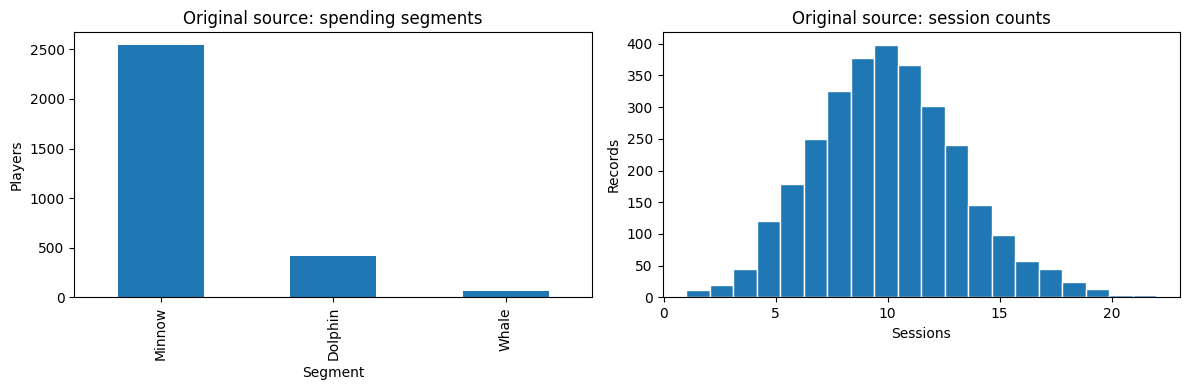

Missing values in the original file:


,missing_rows
UserID,0
Age,60
Gender,60
Country,60
Device,60
GameGenre,60
SessionCount,0
AverageSessionLength,0
SpendingSegment,0
InAppPurchaseAmount,136


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
source['SpendingSegment'].value_counts().reindex(['Minnow', 'Dolphin', 'Whale']).plot.bar(ax=axes[0])
axes[0].set_title('Original source: spending segments')
axes[0].set_xlabel('Segment')
axes[0].set_ylabel('Players')

sessions = pd.to_numeric(source['SessionCount'], errors='coerce').dropna()
axes[1].hist(sessions, bins=20, edgecolor='white')
axes[1].set_title('Original source: session counts')
axes[1].set_xlabel('Sessions')
axes[1].set_ylabel('Records')
plt.tight_layout()
plt.show()
print('Missing values in the original file:')
display(source.isna().sum().to_frame('missing_rows'))


### Step 1 — Decide how many rows to create

We keep the Kaggle rows, make simulated rows, and reserve 1% of the final dataset for deliberate duplicates.

In [15]:
# Same seed = same random choices each time you run the notebook.
rng = np.random.default_rng(SEED)

number_of_duplicates = round(FINAL_ROWS * 0.01)
number_of_simulated = FINAL_ROWS - len(source) - number_of_duplicates

print('Original rows:', len(source))
print('Simulated rows to create:', number_of_simulated)
print('Duplicate rows to add later:', number_of_duplicates)


Original rows: 3024
Simulated rows to create: 244476
Duplicate rows to add later: 2500


### Step 2 — Make simulated player rows

We sample existing players **with replacement**. That means a source player may be selected more than once. The small changes below make numeric values vary, but these rows remain simulated—not new measured players.

In [16]:
# Copy source patterns into a new table.
simulated = source.iloc[
    rng.integers(0, len(source), size=number_of_simulated)
].reset_index(drop=True).copy()

# Slightly vary age while keeping normal values in a plausible range.
age = pd.to_numeric(simulated['Age'], errors='coerce')
simulated['Age'] = np.where(
    age.notna(), np.clip(np.rint(age + rng.normal(0, 3, len(simulated))), 13, 75), np.nan
)

# Vary gameplay sessions and session length a little.
sessions = pd.to_numeric(simulated['SessionCount'], errors='coerce').fillna(8).to_numpy()
simulated['SessionCount'] = np.maximum(
    1, np.rint(sessions * rng.lognormal(0, 0.25, len(simulated)))
).astype(int)

duration = pd.to_numeric(simulated['AverageSessionLength'], errors='coerce').fillna(15).to_numpy()
simulated['AverageSessionLength'] = (duration * rng.lognormal(0, 0.18, len(simulated))).round(2)

print('Simulated table shape:', simulated.shape)
display(simulated.head())


Simulated table shape: (244476, 13)


,UserID,Age,Gender,Country,Device,GameGenre,SessionCount,AverageSessionLength,SpendingSegment,InAppPurchaseAmount,FirstPurchaseDaysAfterInstall,PaymentMethod,LastPurchaseDate
0,d4aced3a-f4f4-4d65-b9ce-79dc1a4d480c,51.0,Male,Iran,Android,MOBA,15,6.26,Minnow,4.13,20.0,Credit Card,2025-05-05
1,e5135044-8a84-4acc-9a32-ec31225ce96c,24.0,Male,Iran,Android,Battle Royale,10,15.75,Dolphin,444.51,13.0,Paypal,2025-03-07
2,f13a3307-7fd7-41d9-b0ae-18b9ab80ecad,31.0,Male,Brazil,Android,Fighting,11,16.69,Dolphin,424.94,12.0,Gift Card,2025-07-18
3,52463f64-7562-480b-a045-cb5a70ddafcb,37.0,Female,Sweden,Android,MMORPG,11,12.73,Minnow,17.20,6.0,Google Pay,2025-07-24
4,7e93e24d-d404-40ff-9789-151f5592fb60,42.0,NaN,India,Android,MMORPG,5,5.14,Minnow,4.04,17.0,Paypal,2025-06-06


### Step 3 — Combine rows and create the 10 extra features

First combine the original and simulated rows. Then create the extra features for **every row**, so the original rows will not be blank in these newly added columns. The formulas are simple simulation assumptions linked to activity or game genre.

In [17]:
data = pd.concat([source, simulated], ignore_index=True)

# Use one consistent ID format for every player; IDs do not reveal row origin.
player_numbers = rng.integers(0, 10**15, size=len(data), dtype=np.int64)
data['UserID'] = ['PLAYER' + str(number).zfill(15) for number in player_numbers]

# Short names make the feature formulas easier to read.
n = len(data)
sessions = pd.to_numeric(data['SessionCount'], errors='coerce').fillna(8).clip(lower=1).to_numpy()
genre = data['GameGenre'].astype('string').fillna('')
last_purchase = pd.to_datetime(data['LastPurchaseDate'], errors='coerce')

# 1. Marketing source for the player's install.
data['AcquisitionChannel'] = rng.choice(
    ['Organic', 'Paid Social', 'Search Ads', 'Influencer', 'Referral', 'Cross-promotion'],
    size=n, p=[.25, .24, .14, .12, .13, .12]
)

# 2. Install date: usually earlier than last purchase; use a fallback if date is missing.
days_before_purchase = rng.integers(0, 901, size=n)
install_date = last_purchase - pd.to_timedelta(days_before_purchase, unit='D')
fallback_date = pd.Timestamp('2025-01-01') - pd.to_timedelta(rng.integers(0, 901, size=n), unit='D')
data['InstallDate'] = install_date.where(last_purchase.notna(), fallback_date)

# 3-6. Activity / engagement features.
data['ActiveDays30d'] = np.clip(rng.poisson(np.clip(sessions * .65, 1, 28)), 1, 30)
data['PlayerLevel30d'] = np.maximum(1, np.rint(sessions * rng.uniform(.5, 2.0, n))).astype(int)
data['AdsWatched30d'] = rng.poisson(5 + 3 * genre.str.contains('Puzzle', case=False, regex=False).to_numpy())
data['SocialActions30d'] = rng.poisson(4 + 3 * genre.str.contains('MOBA', case=False, regex=False).to_numpy())

# 7-8. Yes/No engagement indicators; more active players have a higher probability.
guild_probability = np.clip(.18 + sessions / 45, .18, .78)
push_probability = np.clip(.38 + sessions / 60, .38, .80)
data['GuildMember'] = np.where(rng.random(n) < guild_probability, 'Yes', 'No')
data['PushNotificationsOptIn'] = np.where(rng.random(n) < push_probability, 'Yes', 'No')

# 9-10. Approximate purchase count and win rate.
data['PurchaseCount30d'] = rng.poisson(np.clip(sessions / 7, 0, 7)).astype(int)
data['WinRate'] = np.clip(rng.beta(4, 6, n) + rng.normal(0, .04, n), 0, 1).round(3)

print('Combined table shape:', data.shape)
print('New feature columns:', ['AcquisitionChannel','InstallDate','ActiveDays30d','PlayerLevel30d','AdsWatched30d','SocialActions30d','GuildMember','PushNotificationsOptIn','PurchaseCount30d','WinRate'])


Combined table shape: (247500, 23)
New feature columns: ['AcquisitionChannel', 'InstallDate', 'ActiveDays30d', 'PlayerLevel30d', 'AdsWatched30d', 'SocialActions30d', 'GuildMember', 'PushNotificationsOptIn', 'PurchaseCount30d', 'WinRate']


### Step 4 — Add data-quality problems on purpose

These are practice examples for the cleaning stage: missing values, inconsistent labels, mixed date formats and units, duplicates, outliers, and impossible values. We apply the issues to the combined dataset, not only to one type of row.

In [18]:
# Helper: randomly choose rows for one deliberate issue.
def choose_rows(rate):
    count = max(1, int(rate * len(data)))
    return rng.choice(data.index.to_numpy(), size=count, replace=False)

# A. Missing values in several columns, at different rates.
missing_rates = {
    'Age': .025, 'Gender': .018, 'Country': .035,
    'AverageSessionLength': .04, 'AcquisitionChannel': .05,
    'FirstPurchaseDaysAfterInstall': .12, 'PaymentMethod': .045,
    'LastPurchaseDate': .03, 'InAppPurchaseAmount': .025,
    'SessionCount': .02, 'ActiveDays30d': .015,
}
for column, rate in missing_rates.items():
    data.loc[choose_rows(rate), column] = np.nan

# B. Different spellings / capitalization for some categories.
label_variations = {
    'Device': {'Android': 'android', 'iOS': 'IOS'},
    'Country': {'UAE': 'United Arab Emirates', 'USA': 'usa', 'UK': 'United Kingdom'},
    'GameGenre': {'Battle Royale': 'BattleRoyale', 'Action RPG': 'action rpg'},
    'SpendingSegment': {'Whale': 'whale', 'Dolphin': 'DOLPHIN', 'Minnow': 'Minnow '},
    'PaymentMethod': {'PayPal': 'Paypal', 'Credit Card': 'CreditCard', 'Google Pay': 'GooglePay'},
}
for column, replacements in label_variations.items():
    selected = choose_rows(.02)
    data.loc[selected, column] = data.loc[selected, column].map(
        lambda value: replacements.get(value, value) if pd.notna(value) else value
    )

# C. Mixed date formats. Convert these columns to text because they now contain mixed formats.
for column, rate, date_format in [
    ('InstallDate', .12, '%m/%d/%Y'),
    ('LastPurchaseDate', .10, '%d-%m-%Y'),
]:
    data[column] = data[column].astype(object)
    selected = choose_rows(rate)
    parsed_dates = pd.to_datetime(data.loc[selected, column], errors='coerce')
    data.loc[selected, column] = parsed_dates.dt.strftime(date_format)

# D. Mixed units / types: some durations become seconds-as-text, some amounts include '$'.
data['AverageSessionLength'] = data['AverageSessionLength'].astype(object)
selected = choose_rows(.01)
seconds = pd.to_numeric(data.loc[selected, 'AverageSessionLength'], errors='coerce') * 60
data.loc[selected, 'AverageSessionLength'] = seconds.round().astype('Int64').astype(str) + ' sec'

data['InAppPurchaseAmount'] = data['InAppPurchaseAmount'].astype(object)
selected = choose_rows(.01)
amount = pd.to_numeric(data.loc[selected, 'InAppPurchaseAmount'], errors='coerce').fillna(0)
data.loc[selected, 'InAppPurchaseAmount'] = '$' + amount.round(2).astype(str)

# E. Impossible values and outliers.
selected = choose_rows(.003)
data.loc[selected, 'Age'] = -rng.integers(1, 10, len(selected))
selected = choose_rows(.002)
data.loc[selected, 'SessionCount'] = -rng.integers(1, 30, len(selected))
selected = choose_rows(.001)
data.loc[selected, 'AverageSessionLength'] = rng.uniform(240, 900, len(selected))
selected = choose_rows(.001)
data.loc[selected, 'WinRate'] = rng.uniform(1.2, 2.0, len(selected))
data.loc[data.index[0], 'InstallDate'] = '2035-01-01'  # Deliberately in the future.

print('Quality issues injected. Current shape:', data.shape)


Quality issues injected. Current shape: (247500, 23)


### Step 5 — Add duplicates and save

We copy 1% of rows exactly. The duplicates are intentional, so you can detect and handle them during cleaning.

In [19]:
duplicates = data.sample(n=number_of_duplicates, random_state=SEED + 77)
data = pd.concat([data, duplicates], ignore_index=True)

assert len(data) == FINAL_ROWS, f'Expected {FINAL_ROWS:,} rows, got {len(data):,}'
assert data.shape[1] >= 20, 'The dataset needs at least 20 columns.'

data.to_csv(OUTPUT_FILENAME, index=False)
print('Final size:', data.shape)
print('Exact duplicate rows:', int(data.duplicated().sum()))
print('Saved as:', OUTPUT_FILENAME)
expanded = data  # Keep the same variable name used in the review cells below.


Final size: (250000, 23)
Exact duplicate rows: 2500
Saved as: mobile_game_players_expanded_dirty.csv


## 4. After generation: compare before and after

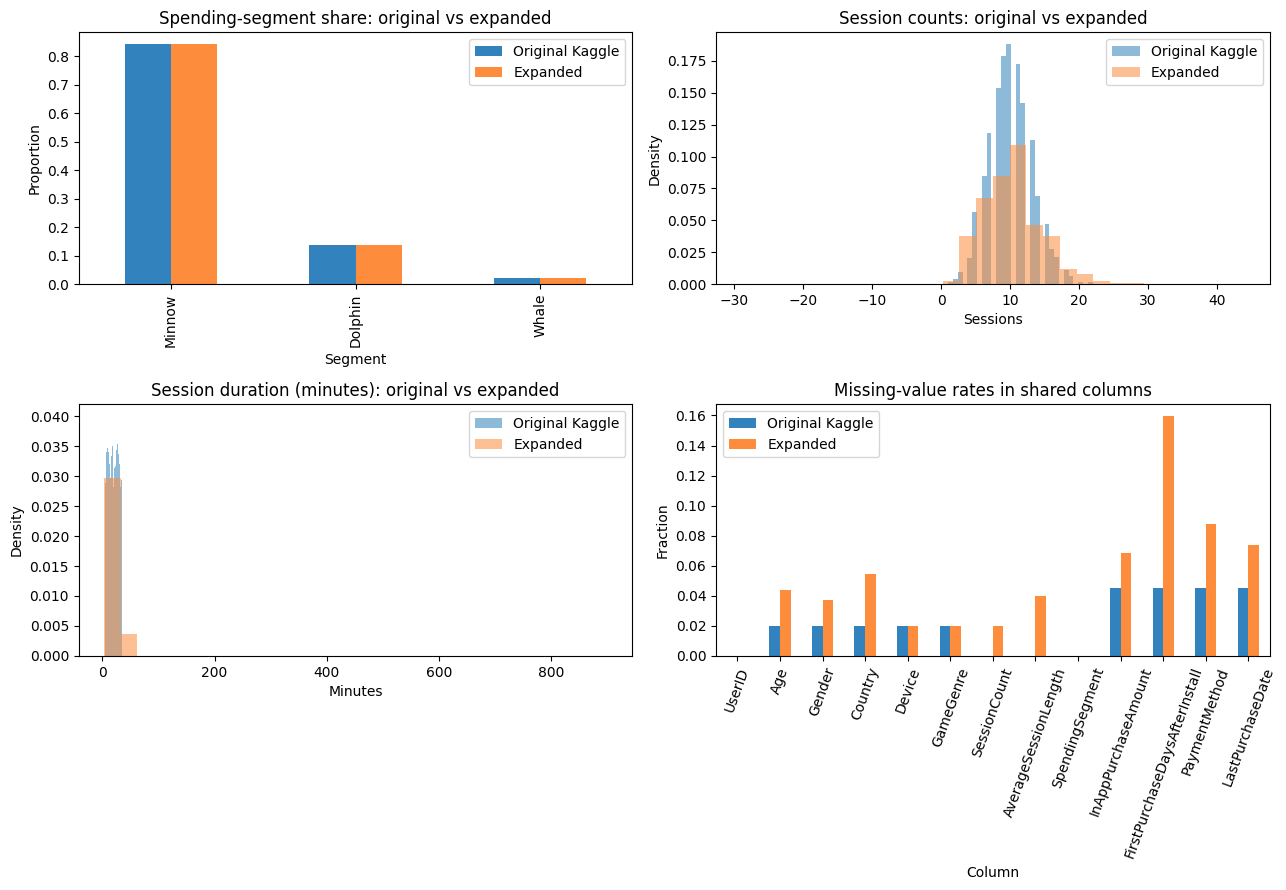

In [20]:
# Clean label variations for the chart only; the dataset itself stays unchanged.
def clean_segment_for_plot(series):
    return (series.astype('string').str.strip().str.lower()
            .map({'minnow': 'Minnow', 'dolphin': 'Dolphin', 'whale': 'Whale'}))

# Use consistent colors for the source and expanded dataset.
source_color = '#3182bd'
expanded_color = '#fd8d3c'

base_share = (clean_segment_for_plot(source['SpendingSegment'])
              .value_counts(normalize=True)
              .reindex(['Minnow', 'Dolphin', 'Whale']))
expanded_share = (clean_segment_for_plot(expanded['SpendingSegment'])
                  .value_counts(normalize=True)
                  .reindex(['Minnow', 'Dolphin', 'Whale']))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Compare proportions of each spending segment.
segment_comparison = pd.DataFrame({
    'Original Kaggle': base_share,
    'Expanded': expanded_share
})
segment_comparison.plot.bar(
    ax=axes[0, 0], color=[source_color, expanded_color]
)
axes[0, 0].set_title('Spending-segment share: original vs expanded')
axes[0, 0].set_xlabel('Segment')
axes[0, 0].set_ylabel('Proportion')

# 2. Compare session-count distributions.
for label, values, color in [
    ('Original Kaggle', source['SessionCount'], source_color),
    ('Expanded', expanded['SessionCount'], expanded_color),
]:
    values = pd.to_numeric(values, errors='coerce').dropna()
    axes[0, 1].hist(values, bins=30, density=True, alpha=.55, label=label, color=color)
axes[0, 1].set_title('Session counts: original vs expanded')
axes[0, 1].set_xlabel('Sessions')
axes[0, 1].set_ylabel('Density')
axes[0, 1].legend()

# Convert intentional values such as "600 sec" to minutes for plotting only.
def duration_minutes(series):
    text = series.astype('string').str.strip()
    seconds = text.str.extract(r'^([0-9.]+)\s*sec$', expand=False)
    numbers = pd.to_numeric(text, errors='coerce')
    seconds_mask = seconds.notna()
    numbers.loc[seconds_mask] = (
        pd.to_numeric(seconds[seconds_mask], errors='coerce') / 60
    )
    return numbers

# 3. Compare session duration.
for label, values, color in [
    ('Original Kaggle', source['AverageSessionLength'], source_color),
    ('Expanded', expanded['AverageSessionLength'], expanded_color),
]:
    values = duration_minutes(values).dropna()
    axes[1, 0].hist(values, bins=30, density=True, alpha=.55, label=label, color=color)
axes[1, 0].set_title('Session duration (minutes): original vs expanded')
axes[1, 0].set_xlabel('Minutes')
axes[1, 0].set_ylabel('Density')
axes[1, 0].legend()

# 4. Compare missing-value rates in columns that existed in Kaggle.
shared_columns = [column for column in source.columns if column in expanded.columns]
missing_comparison = pd.DataFrame({
    'Original Kaggle': source[shared_columns].isna().mean(),
    'Expanded': expanded[shared_columns].isna().mean(),
})
missing_comparison.plot.bar(
    ax=axes[1, 1], color=[source_color, expanded_color]
)
axes[1, 1].set_title('Missing-value rates in shared columns')
axes[1, 1].set_ylabel('Fraction')
axes[1, 1].set_xlabel('Column')
axes[1, 1].tick_params(axis='x', rotation=70)

plt.tight_layout()
plt.show()


## 5. Inspect and download

In [21]:
print('Final dimensions:', expanded.shape)
print('Exact duplicate rows:', int(expanded.duplicated().sum()))
print('Missing values (%):')
display((expanded.isna().mean() * 100).round(2).to_frame('missing_percent'))
print('Target labels (some variations are deliberate):')
display(expanded['SpendingSegment'].value_counts(dropna=False).to_frame('records'))


Final dimensions: (250000, 23)
Exact duplicate rows: 2500
Missing values (%):


,missing_percent
UserID,0.00
Age,4.40
Gender,3.75
Country,5.43
Device,2.00
GameGenre,1.99
SessionCount,1.99
AverageSessionLength,3.96
SpendingSegment,0.00
InAppPurchaseAmount,6.83


Target labels (some variations are deliberate):


,records
SpendingSegment,
Minnow,206198
Dolphin,33343
Whale,5464
Minnow,4213
DOLPHIN,674
whale,108


In [22]:
from google.colab import files
files.download(OUTPUT_FILENAME)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## What is original and what is generated?

- Original source: Kaggle CSV, 3,024 records and 13 columns
- Final dataset: 250,000 records and 23 columns.

**Original records:** Retained in the dataset. Additional simulated records are created by resampling original rows and slightly changing some numeric values. One percent of the final dataset consists of deliberately appended duplicate records.

-  1% of the final dataset consists of deliberately appended duplicate records.

- Ten added features: `AcquisitionChannel`, `InstallDate`, `ActiveDays30d`, `PlayerLevel30d`, `AdsWatched30d`, `SocialActions30d`, `GuildMember`, `PushNotificationsOptIn`, `PurchaseCount30d`, and `WinRate`.


**Deliberate data-quality issues:** Missing values in several columns; inconsistent category spellings and capitalization; mixed date formats; session durations stored in seconds as text; purchase amounts stored as currency text; exact duplicate records; negative ages and session counts; unusually high session durations; win rates above 1; and a future install date.
